In [1]:

import pandas as pd
import numpy as np

# Road accidents by Colombo police area
data = {
    "Police_Area": [
        "Modera", "Grandpass", "Kotahena", "Dematagoda",
        "Borella", "Maradana", "Fort", "Pettah",
        "Slave Island", "Colpetty", "Cinnamon Gardens",
        "Bambalapitiya", "Wellawatte", "Narahenpita",
        "Foreshore Ports", "Kirulapone", "Harbour",
        "Maligawatte", "Keselwatte", "Bluemendhal",
        "Dam Street", "Mattakkuliya", "Wolfendhal"
    ],
    2020: [
        28,161,73,54,314,64,80,44,35,170,324,
        136,145,84,21,64,22,32,13,4,11,31,5
    ],
    2021: [
        23,188,41,70,305,69,78,51,48,112,274,
        120,88,54,32,84,18,38,14,7,7,31,8
    ],
    2022: [
        26,212,41,69,277,66,112,38,44,154,283,
        106,68,67,np.nan,63,23,57,16,1,12,17,1
    ],
    2023: [
        18,186,67,67,258,77,96,54,47,151,308,
        95,45,78,54,50,15,50,25,5,14,18,1
    ],
    2024: [
        12,147,37,78,234,93,59,30,41,112,257,
        82,65,137,40,31,17,48,21,4,20,17,41
    ]
}

# Create DataFrame
df = pd.DataFrame(data)

# Convert wide format to long format
df_long = df.melt(
    id_vars="Police_Area",
    var_name="Year",
    value_name="Accident_Count"
)

df_long["Year"] = df_long["Year"].astype(int)

# Save dataset
df_long.to_csv("colombo_road_accidents.csv", index=False)

# Display dataset
display(df_long.head(10))

print("Dataset Shape:", df_long.shape)
print("Missing Values:")
print(df_long.isnull().sum())

# Download CSV
from google.colab import files
files.download("colombo_road_accidents.csv")


,Police_Area,Year,Accident_Count
0,Modera,2020,28.0
1,Grandpass,2020,161.0
2,Kotahena,2020,73.0
3,Dematagoda,2020,54.0
4,Borella,2020,314.0
5,Maradana,2020,64.0
6,Fort,2020,80.0
7,Pettah,2020,44.0
8,Slave Island,2020,35.0
9,Colpetty,2020,170.0


Dataset Shape: (115, 3)
Missing Values:
Police_Area       0
Year              0
Accident_Count    1
dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Yearly Accident Counts:


,Accident_Count
Year,
2020,1915.0
2021,1760.0
2022,1753.0
2023,1779.0
2024,1623.0


Top 10 Police Areas:


,Accident_Count
Police_Area,
Cinnamon Gardens,1446.0
Borella,1388.0
Grandpass,894.0
Colpetty,699.0
Bambalapitiya,539.0
Fort,425.0
Narahenpita,420.0
Wellawatte,411.0
Maradana,369.0


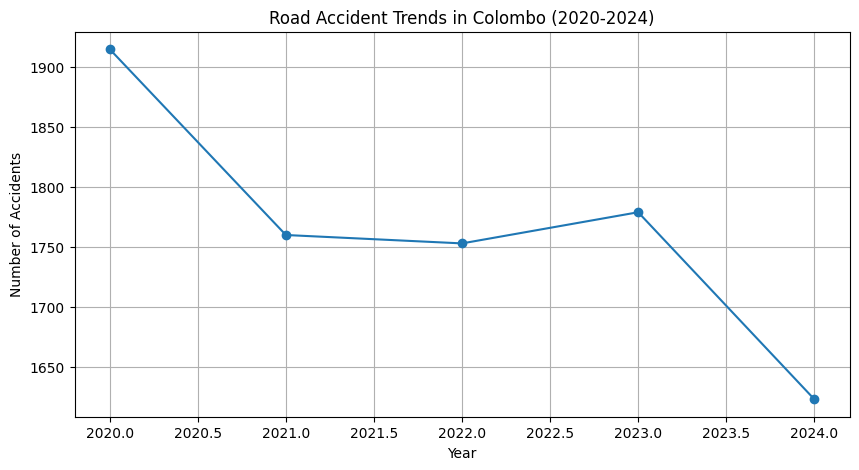

In [2]:

# 1. Total accidents by year
yearly_accidents = (
    df_long.groupby("Year")["Accident_Count"]
    .sum()
)

print("Yearly Accident Counts:")
display(yearly_accidents)

# 2. Top 10 police areas
top_areas = (
    df_long.groupby("Police_Area")["Accident_Count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Police Areas:")
display(top_areas)

# 3. Create a yearly trend chart
import matplotlib.pyplot as plt

yearly_accidents.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Road Accident Trends in Colombo (2020-2024)")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.grid(True)
plt.show()


In [3]:

# STEP 5: DATA CLEANING

# Check dataset information
print("Dataset Information:")
df_long.info()

# Check missing values
print("\nMissing Values:")
print(df_long.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df_long.duplicated().sum())

# Check negative accident counts
print("\nNegative Accident Counts:")
print((df_long["Accident_Count"] < 0).sum())

# Check unique years
print("\nAvailable Years:")
print(sorted(df_long["Year"].unique()))

# Check unique police areas
print("\nNumber of Police Areas:")
print(df_long["Police_Area"].nunique())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115 entries, 0 to 114
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Police_Area     115 non-null    object 
 1   Year            115 non-null    int64  
 2   Accident_Count  114 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 2.8+ KB

Missing Values:
Police_Area       0
Year              0
Accident_Count    1
dtype: int64

Duplicate Records:
0

Negative Accident Counts:
0

Available Years:
[np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Number of Police Areas:
23


In [4]:

# Create a copy of original data
clean_df = df_long.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Remove records with invalid negative counts
clean_df = clean_df[
    clean_df["Accident_Count"].isna() |
    (clean_df["Accident_Count"] >= 0)
]

# Check missing records
print("Missing Values After Cleaning:")
print(clean_df.isnull().sum())

# Save cleaned dataset
clean_df.to_csv("cleaned_road_accidents.csv", index=False)

print("\nCleaned Dataset Shape:", clean_df.shape)

display(clean_df.head())


Missing Values After Cleaning:
Police_Area       0
Year              0
Accident_Count    1
dtype: int64

Cleaned Dataset Shape: (115, 3)


,Police_Area,Year,Accident_Count
0,Modera,2020,28.0
1,Grandpass,2020,161.0
2,Kotahena,2020,73.0
3,Dematagoda,2020,54.0
4,Borella,2020,314.0


In [5]:

# Total accidents by year
yearly_analysis = (
    clean_df.groupby("Year")["Accident_Count"]
    .agg(["sum", "mean"])
    .reset_index()
)

yearly_analysis.columns = [
    "Year", "Total_Accidents", "Average_Per_Area"
]

display(yearly_analysis)

# Identify highest accident year
highest_year = yearly_analysis.loc[
    yearly_analysis["Total_Accidents"].idxmax()
]

print("Year with highest recorded accidents:")
print(highest_year)


,Year,Total_Accidents,Average_Per_Area
0,2020,1915.0,83.260870
1,2021,1760.0,76.521739
2,2022,1753.0,79.681818
3,2023,1779.0,77.347826
4,2024,1623.0,70.565217


Year with highest recorded accidents:
Year                2020.00000
Total_Accidents     1915.00000
Average_Per_Area      83.26087
Name: 0, dtype: float64


In [6]:

# Total accidents by police area
area_analysis = (
    clean_df.groupby("Police_Area")["Accident_Count"]
    .sum(min_count=1)
    .sort_values(ascending=False)
    .reset_index()
)

area_analysis.columns = [
    "Police_Area", "Total_Accidents"
]

print("Top 10 Police Areas:")
display(area_analysis.head(10))

print("Lowest 10 Police Areas:")
display(area_analysis.tail(10))


Top 10 Police Areas:


,Police_Area,Total_Accidents
0,Cinnamon Gardens,1446.0
1,Borella,1388.0
2,Grandpass,894.0
3,Colpetty,699.0
4,Bambalapitiya,539.0
5,Fort,425.0
6,Narahenpita,420.0
7,Wellawatte,411.0
8,Maradana,369.0
9,Dematagoda,338.0


Lowest 10 Police Areas:


,Police_Area,Total_Accidents
13,Pettah,217.0
14,Slave Island,215.0
15,Foreshore Ports,147.0
16,Mattakkuliya,114.0
17,Modera,107.0
18,Harbour,95.0
19,Keselwatte,89.0
20,Dam Street,64.0
21,Wolfendhal,56.0
22,Bluemendhal,21.0


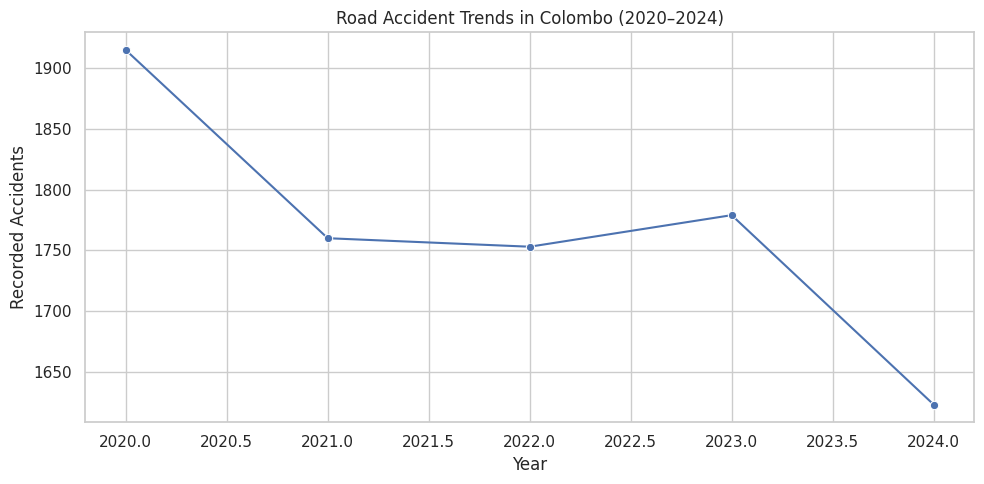

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis,
    x="Year",
    y="Total_Accidents",
    marker="o"
)

plt.title("Road Accident Trends in Colombo (2020–2024)")
plt.xlabel("Year")
plt.ylabel("Recorded Accidents")
plt.tight_layout()
plt.show()


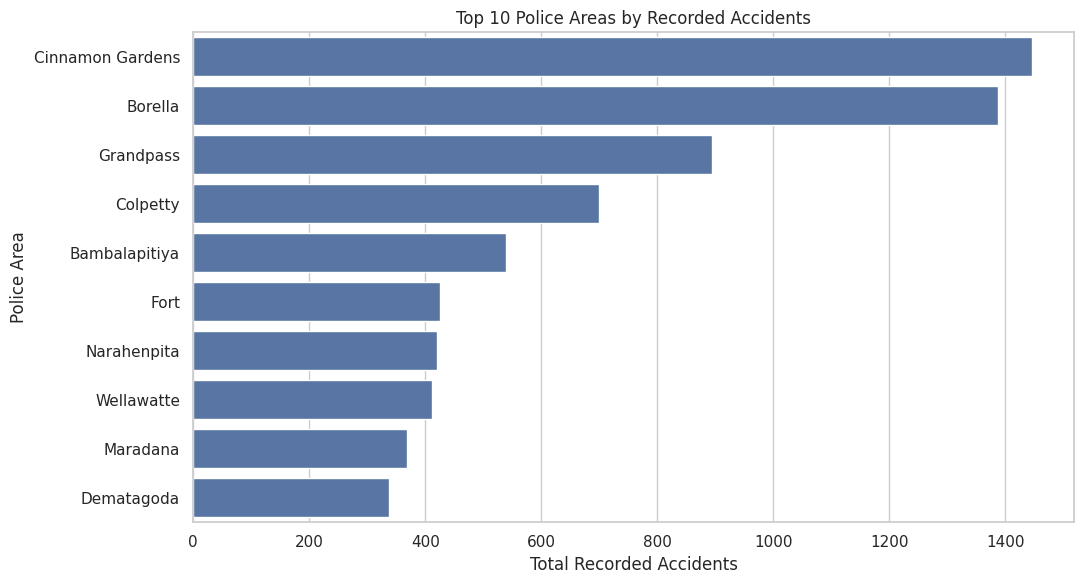

In [8]:

top_10 = area_analysis.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10,
    x="Total_Accidents",
    y="Police_Area"
)

plt.title("Top 10 Police Areas by Recorded Accidents")
plt.xlabel("Total Recorded Accidents")
plt.ylabel("Police Area")
plt.tight_layout()
plt.show()


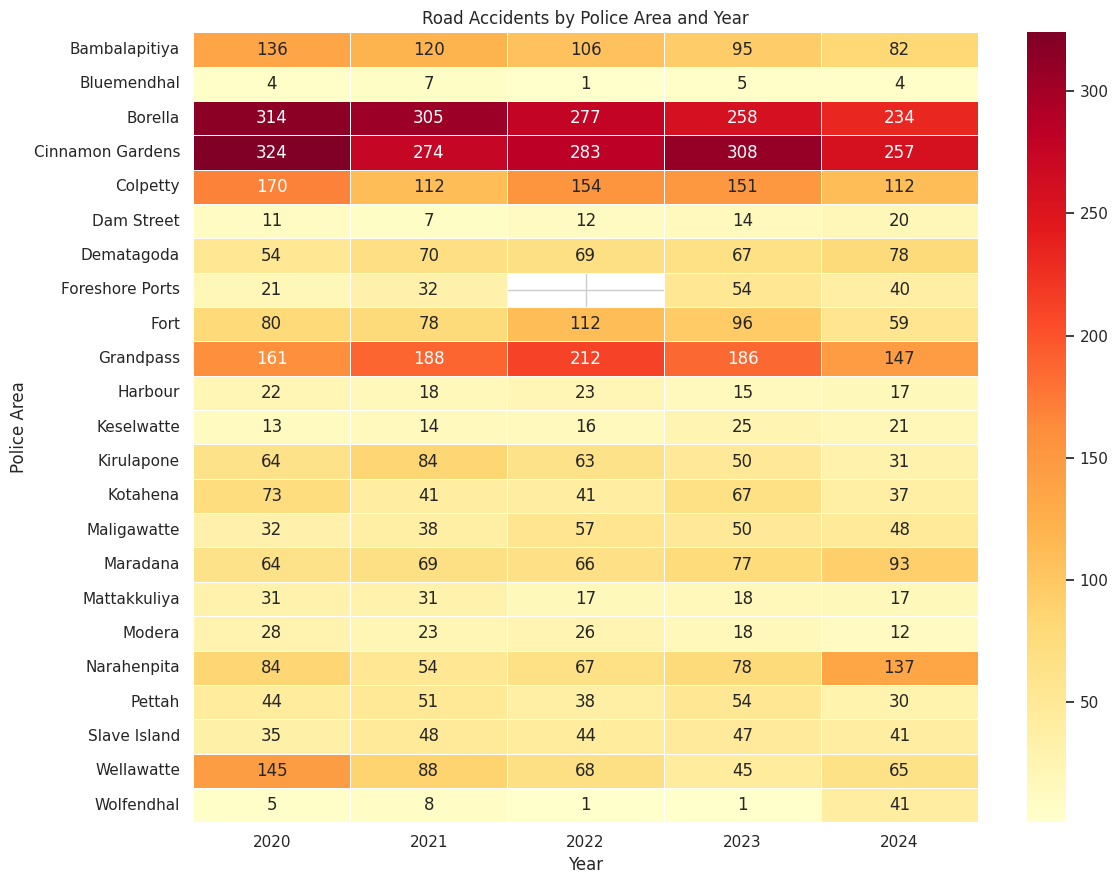

In [9]:

pivot_data = clean_df.pivot(
    index="Police_Area",
    columns="Year",
    values="Accident_Count"
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    pivot_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Road Accidents by Police Area and Year")
plt.xlabel("Year")
plt.ylabel("Police Area")
plt.tight_layout()
plt.show()


In [10]:

# Export analysis results
yearly_analysis.to_csv("yearly_analysis.csv", index=False)

area_analysis.to_csv("area_analysis.csv", index=False)

clean_df.to_csv("cleaned_road_accidents.csv", index=False)

print("All analysis files saved successfully!")

from google.colab import files

files.download("cleaned_road_accidents.csv")
files.download("yearly_analysis.csv")
files.download("area_analysis.csv")


All analysis files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>